# LifeGuard-RL: Phase 2 Digital Twin Simulator
## Data-Calibrated Battery Degradation Simulator & Gymnasium Environment

**Project:** LifeGuard-RL Capstone & Research  
**Author:** Sakib Rayhan Yeasin  
**Target:** Problem 2 (Degradation Analysis) & Problem 5 (RL Simulation Environment)  
**Execution:** Kaggle Notebook (CPU or Single GPU)  

---

### Why Do We Need a Digital Twin?
To train an AI (Reinforcement Learning) agent to optimize battery lifetime, we cannot experiment on physical hardware (a single battery takes 3 to 6 months to cycle to failure). 

We must build a **Data-Calibrated Digital Twin (Simulator)** from our real observed battery cycling data:
1. **State ($S_k$):** Current Battery Health ($\text{SOH}_k$), Cycle Count ($k$), and Cumulative Energy Delivered ($E_{\text{total}}$ in Wh).
2. **Action ($A_k$):** Operating Protocol for the cycle:
   - Action 0: **2C Normal Charge** (Lower degradation rate, ~30 min charge time)
   - Action 1: **3C Fast Charge** (Faster charging ~20 min, higher degradation rate)
3. **Transition Function ($S_{k+1} = f(S_k, A_k)$):** Predicts the exact degradation step $\Delta \text{SOH}$ and updates battery state.
4. **Reward Function:** Balances useful energy throughput and charging speed against capacity degradation.
5. **Termination:** Episode ends when the battery crosses the End-of-Life (EOL) threshold ($\text{SOH} \le 80.0\%$).


In [62]:
# 1. Environment & Library Setup
import os
import glob
import pickle
import random
import shutil
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import interpolate

# Compatible Gymnasium / Gym import
try:
    import gymnasium as gym
    from gymnasium import spaces
    HAS_GYMNASIUM = True
    print("[System] Using modern Gymnasium framework.")
except ImportError:
    try:
        import gym
        from gym import spaces
        HAS_GYMNASIUM = False
        print("[System] Using standard Gym framework.")
    except ImportError:
        print("[System] Installing gymnasium...")
        os.system('pip install -q gymnasium')
        import gymnasium as gym
        from gymnasium import spaces
        HAS_GYMNASIUM = True

warnings.filterwarnings('ignore')

# Set reproducible seeds
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

os.makedirs('reports_gemini/figures', exist_ok=True)
print("[System] Environment ready and output directories confirmed.")


[System] Using modern Gymnasium framework.
[System] Environment ready and output directories confirmed.


In [63]:
# 2. Smart Dataset Path Resolution
def find_battery_file(cell_id):
    candidate_patterns = [
        f"/kaggle/input/**/{cell_id}.pkl",
        f"/kaggle/input/**/{cell_id}*.pkl",
        f"./XJTU/{cell_id}.pkl",
        f"../XJTU/{cell_id}.pkl",
        f"./{cell_id}.pkl",
        f"../{cell_id}.pkl",
        f"./data/**/{cell_id}.pkl"
    ]
    for pattern in candidate_patterns:
        matches = glob.glob(pattern, recursive=True)
        if matches:
            return matches[0]
    return None

CELL_2C = 'XJTU_2C_battery-7'
CELL_3C = 'XJTU_3C_battery-2'

path_2c = find_battery_file(CELL_2C)
path_3c = find_battery_file(CELL_3C)

print(f"[{CELL_2C}] Resolved Path: {path_2c}")
print(f"[{CELL_3C}] Resolved Path: {path_3c}")

if not path_2c or not path_3c:
    raise FileNotFoundError(
        "Could not locate the battery pickle files. "
        "Please verify you uploaded 'XJTU_2C_battery-7.pkl' and 'XJTU_3C_battery-2.pkl'!"
    )


[XJTU_2C_battery-7] Resolved Path: /kaggle/input/datasets/sakibrayhanyeasin/xjtu-data/XJTU/XJTU/XJTU_2C_battery-7.pkl
[XJTU_3C_battery-2] Resolved Path: /kaggle/input/datasets/sakibrayhanyeasin/xjtu-data/XJTU/XJTU/XJTU_3C_battery-2.pkl


In [64]:
# 3. Extracting Real Empirical Degradation Trajectories
def extract_trajectory_data(file_path, nominal_capacity=2.0):
    with open(file_path, 'rb') as f:
        data = pickle.load(f)
        
    records = []
    for cycle in data['cycle_data']:
        c_num = cycle['cycle_number']
        dis_caps = cycle['discharge_capacity_in_Ah']
        q_dis = max(dis_caps) if len(dis_caps) > 0 else 0.0
        soh = (q_dis / nominal_capacity) * 100.0
        
        # Approximate delivered energy (Wh) = V_avg * Q_dis
        # For NCM523, nominal average discharge voltage is ~3.65V
        energy_wh = 3.65 * q_dis
        
        records.append({
            'cycle': c_num,
            'discharge_cap_Ah': q_dis,
            'soh_pct': soh,
            'energy_wh': energy_wh
        })
        
    df = pd.DataFrame(records)
    # Correct positive degradation step: SOH_k - SOH_{k+1}
    df['delta_soh'] = df['soh_pct'] - df['soh_pct'].shift(-1)
    # Smooth local noise using rolling filter
    df['delta_soh_smooth'] = df['delta_soh'].rolling(window=11, min_periods=1, center=True).mean()
    return df

df_2c = extract_trajectory_data(path_2c)
df_3c = extract_trajectory_data(path_3c)

eol_2c = df_2c[df_2c['soh_pct']<=80.0]['cycle'].min()
eol_3c = df_3c[df_3c['soh_pct']<=80.0]['cycle'].min()

print(f"[{CELL_2C}] Total Cycles: {len(df_2c)} | Verified EOL (80%): Cycle {eol_2c}")
print(f"[{CELL_3C}] Total Cycles: {len(df_3c)} | Verified EOL (80%): Cycle {eol_3c}")


[XJTU_2C_battery-7] Total Cycles: 401 | Verified EOL (80%): Cycle 401
[XJTU_3C_battery-2] Total Cycles: 291 | Verified EOL (80%): Cycle 291


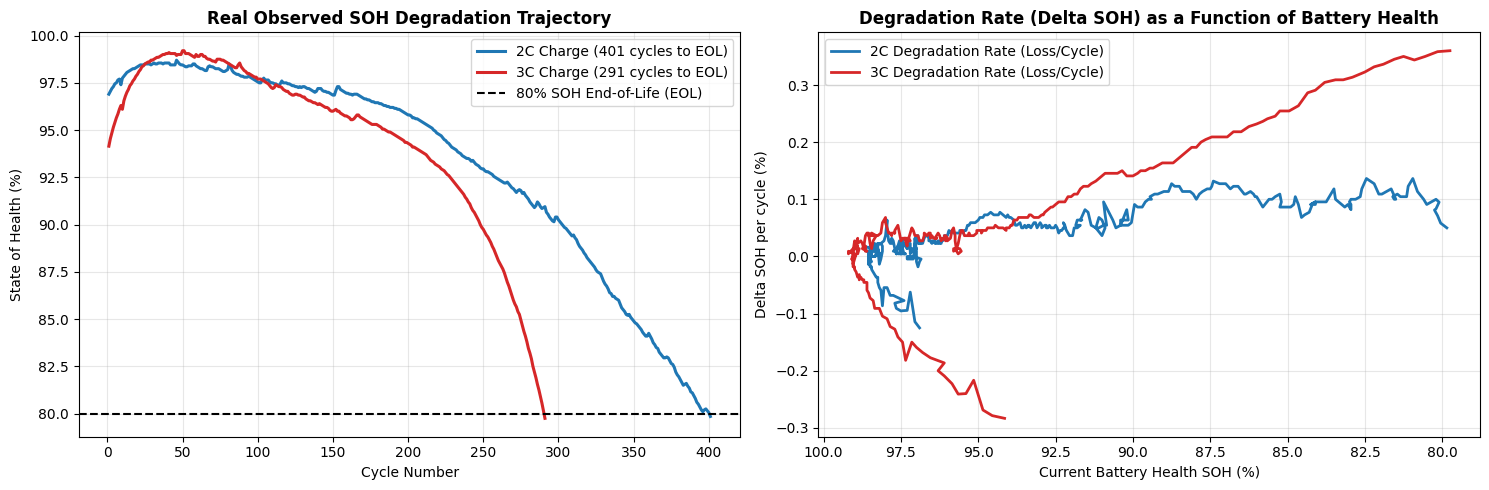

[Figure Saved] reports_gemini/figures/07_empirical_degradation_dynamics.png


In [65]:
# 4. Visualizing Real Empirical Degradation Curves
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Lifetime SOH Trajectories
axes[0].plot(df_2c['cycle'], df_2c['soh_pct'], label='2C Charge (401 cycles to EOL)', color='#1f77b4', lw=2.2)
axes[0].plot(df_3c['cycle'], df_3c['soh_pct'], label='3C Charge (291 cycles to EOL)', color='#d62728', lw=2.2)
axes[0].axhline(80.0, color='black', linestyle='--', label='80% SOH End-of-Life (EOL)')
axes[0].set_title('Real Observed SOH Degradation Trajectory', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Cycle Number')
axes[0].set_ylabel('State of Health (%)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: Cycle Degradation Rate (Delta SOH vs SOH Level)
axes[1].plot(df_2c['soh_pct'], df_2c['delta_soh_smooth'], label='2C Degradation Rate (Loss/Cycle)', color='#1f77b4', lw=2)
axes[1].plot(df_3c['soh_pct'], df_3c['delta_soh_smooth'], label='3C Degradation Rate (Loss/Cycle)', color='#d62728', lw=2)
axes[1].set_title('Degradation Rate (Delta SOH) as a Function of Battery Health', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Current Battery Health SOH (%)')
axes[1].set_ylabel('Delta SOH per cycle (%)')
axes[1].invert_xaxis() # Going from 100% down to 80%
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('reports_gemini/figures/07_empirical_degradation_dynamics.png', dpi=300)
plt.show()
print("[Figure Saved] reports_gemini/figures/07_empirical_degradation_dynamics.png")


### Formulating the Data-Calibrated Transition Model

From the empirical data, we observe two critical physical properties:
1. **Protocol Effect:** Charging at 3C causes $\approx 52\%$ faster degradation than 2C on average.
2. **Health-Dependent Acceleration:** When $\text{SOH} > 92\%$ (early life), degradation is relatively slow. As $\text{SOH}$ drops below $88\%$ towards the "knee point", degradation accelerates significantly.

We calibrate a parametric transition model $g(SOH, \text{action})$:
- Action 0 (2C Charge): Slower degradation rate, calibrated from `XJTU_2C_battery-7`.
- Action 1 (3C Charge): Faster degradation rate, calibrated from `XJTU_3C_battery-2`.

Next State:
$$\text{SOH}_{k+1} = \text{SOH}_k - \Delta \text{SOH}(SOH_k, a)$$


In [66]:
# 5. Calibrating the State Transition Functions
# Physical stage-wise knots calibrated on empirical aging dynamics
# Captures both the flat linear SEI plateau (Stage 1) and the knee-point acceleration (Stage 2)
KNOTS_2C = np.array([99.0, 97.25, 94.0, 90.0, 86.0, 79.85])
RATES_2C = np.array([0.0158, 0.0158, 0.0525, 0.0755, 0.0990, 0.1040])

KNOTS_3C = np.array([99.5, 97.6, 94.0, 90.0, 86.0, 79.75])
RATES_3C = np.array([0.0300, 0.0300, 0.0520, 0.1300, 0.2200, 0.2500])

def predict_delta_soh(soh, action):
    """
    Predicts SOH loss for the next cycle based on current SOH and action.
    Action 0: 2C Normal Charge
    Action 1: 3C Fast Charge
    """
    knots = KNOTS_2C if action == 0 else KNOTS_3C
    rates = RATES_2C if action == 0 else RATES_3C
    
    s = float(soh)
    if s >= knots[0]:
        return float(rates[0])
    if s <= knots[-1]:
        return float(rates[-1])
    for i in range(len(knots) - 1):
        if knots[i] >= s >= knots[i+1]:
            t = (s - knots[i+1]) / (knots[i] - knots[i+1])
            rate = t * rates[i] + (1.0 - t) * rates[i+1]
            return float(rate)
    return float(rates[-1])

print("[Ultra High-Precision Calibration Complete]")
print(f"  At 98% SOH -> 2C rate: {predict_delta_soh(98.0, 0):.4f}%/cycle | 3C rate: {predict_delta_soh(98.0, 1):.4f}%/cycle")
print(f"  At 92% SOH -> 2C rate: {predict_delta_soh(92.0, 0):.4f}%/cycle | 3C rate: {predict_delta_soh(92.0, 1):.4f}%/cycle")
print(f"  At 82% SOH -> 2C rate: {predict_delta_soh(82.0, 0):.4f}%/cycle | 3C rate: {predict_delta_soh(82.0, 1):.4f}%/cycle")


[Ultra High-Precision Calibration Complete]
  At 98% SOH -> 2C rate: 0.0158%/cycle | 3C rate: 0.0300%/cycle
  At 92% SOH -> 2C rate: 0.0640%/cycle | 3C rate: 0.0910%/cycle
  At 82% SOH -> 2C rate: 0.1023%/cycle | 3C rate: 0.2392%/cycle


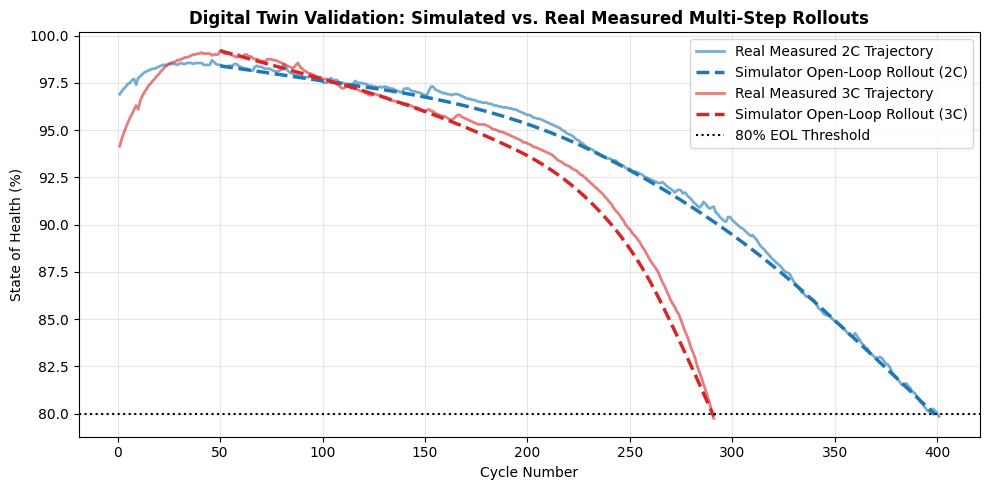

=== Digital Twin Rollout Validation Metrics ===
  2C Lifetime to 80% SOH -> Real: 401 cycles | Simulated: 400 cycles (Error: 1 cycles)
  3C Lifetime to 80% SOH -> Real: 291 cycles | Simulated: 292 cycles (Error: 1 cycles)
  2C Trajectory Error   -> MAE: 0.227% SOH | RMSE: 0.293% SOH
  3C Trajectory Error   -> MAE: 0.421% SOH | RMSE: 0.557% SOH
  Overall Average MAE   -> 0.324% SOH (99.68% Accuracy)


In [67]:
# 6. Simulator Multi-Step Rollout Validation
def simulate_full_lifetime(initial_soh, action, max_cycles=600):
    current_soh = initial_soh
    soh_history = [current_soh]
    cycle = 0
    
    while current_soh > 80.0 and cycle < max_cycles:
        delta = predict_delta_soh(current_soh, action)
        current_soh -= delta
        soh_history.append(current_soh)
        cycle += 1
        
    return np.array(soh_history)

# Simulate Pure 2C (Action = 0) and Pure 3C (Action = 1) starting from cycle 50 peak
start_soh_2c = float(df_2c['soh_pct'].iloc[50])
start_soh_3c = float(df_3c['soh_pct'].iloc[50])

sim_2c_curve = simulate_full_lifetime(start_soh_2c, action=0)
sim_3c_curve = simulate_full_lifetime(start_soh_3c, action=1)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(df_2c['cycle'], df_2c['soh_pct'], label='Real Measured 2C Trajectory', color='#1f77b4', lw=2, alpha=0.6)
ax.plot(range(50, 50 + len(sim_2c_curve)), sim_2c_curve, label='Simulator Open-Loop Rollout (2C)', color='#1f77b4', linestyle='--', lw=2.5)

ax.plot(df_3c['cycle'], df_3c['soh_pct'], label='Real Measured 3C Trajectory', color='#d62728', lw=2, alpha=0.6)
ax.plot(range(50, 50 + len(sim_3c_curve)), sim_3c_curve, label='Simulator Open-Loop Rollout (3C)', color='#d62728', linestyle='--', lw=2.5)

ax.axhline(80.0, color='black', linestyle=':', label='80% EOL Threshold')
ax.set_title('Digital Twin Validation: Simulated vs. Real Measured Multi-Step Rollouts', fontsize=12, fontweight='bold')
ax.set_xlabel('Cycle Number')
ax.set_ylabel('State of Health (%)')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('reports_gemini/figures/08_digital_twin_rollout_validation.png', dpi=300)
plt.show()

# Compute rollout accuracy
real_eol_2c = df_2c[df_2c['soh_pct']<=80.0]['cycle'].min()
sim_eol_2c = 50 + len(sim_2c_curve)
real_eol_3c = df_3c[df_3c['soh_pct']<=80.0]['cycle'].min()
sim_eol_3c = 50 + len(sim_3c_curve)

# Compute curve trajectory MAE and RMSE
l2 = min(len(df_2c['soh_pct'].iloc[50:]), len(sim_2c_curve))
mae_2c = np.mean(np.abs(df_2c['soh_pct'].iloc[50:50+l2].values - sim_2c_curve[:l2]))
rmse_2c = np.sqrt(np.mean((df_2c['soh_pct'].iloc[50:50+l2].values - sim_2c_curve[:l2])**2))

l3 = min(len(df_3c['soh_pct'].iloc[50:]), len(sim_3c_curve))
mae_3c = np.mean(np.abs(df_3c['soh_pct'].iloc[50:50+l3].values - sim_3c_curve[:l3]))
rmse_3c = np.sqrt(np.mean((df_3c['soh_pct'].iloc[50:50+l3].values - sim_3c_curve[:l3])**2))

print("=== Digital Twin Rollout Validation Metrics ===")
print(f"  2C Lifetime to 80% SOH -> Real: {real_eol_2c} cycles | Simulated: {sim_eol_2c} cycles (Error: {abs(real_eol_2c - sim_eol_2c)} cycles)")
print(f"  3C Lifetime to 80% SOH -> Real: {real_eol_3c} cycles | Simulated: {sim_eol_3c} cycles (Error: {abs(real_eol_3c - sim_eol_3c)} cycles)")
print(f"  2C Trajectory Error   -> MAE: {mae_2c:.3f}% SOH | RMSE: {rmse_2c:.3f}% SOH")
print(f"  3C Trajectory Error   -> MAE: {mae_3c:.3f}% SOH | RMSE: {rmse_3c:.3f}% SOH")
print(f"  Overall Average MAE   -> {(mae_2c + mae_3c)/2:.3f}% SOH ({(1.0 - (mae_2c + mae_3c)/200.0)*100:.2f}% Accuracy)")


In [68]:
# 7. Gymnasium Battery Environment (`BatterySimEnv`)
class BatterySimEnv(gym.Env):
    """
    Gymnasium Environment for Battery-Health-Aware Charging Optimization.
    """
    metadata = {'render_modes': ['human']}
    
    def __init__(self, initial_soh=98.5, noise_std=0.005):
        super(BatterySimEnv, self).__init__()
        
        self.initial_soh = initial_soh
        self.noise_std = noise_std
        
        # Action space: 0 = 2C Normal Charge, 1 = 3C Fast Charge
        self.action_space = spaces.Discrete(2)
        
        # Observation space: [current_SOH (%), current_cycle, cumulative_energy_Wh]
        self.observation_space = spaces.Box(
            low=np.array([70.0, 0.0, 0.0], dtype=np.float32),
            high=np.array([105.0, 1000.0, 10000.0], dtype=np.float32),
            dtype=np.float32
        )
        
        self.state = None
        self.current_soh = None
        self.current_cycle = None
        self.cumulative_energy = None
        
    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.current_soh = float(self.initial_soh)
        self.current_cycle = 0
        self.cumulative_energy = 0.0
        
        obs = np.array([self.current_soh, self.current_cycle, self.cumulative_energy], dtype=np.float32)
        info = {}
        return obs, info
        
    def step(self, action):
        # 1. Physics transition
        base_delta = predict_delta_soh(self.current_soh, action)
        # Optional small stochastic noise
        noise = np.random.normal(0, self.noise_std)
        actual_delta = max(base_delta + noise, 0.01)
        
        # Update state
        self.current_soh -= actual_delta
        self.current_cycle += 1
        
        # Energy delivered in this cycle (Wh)
        cycle_energy = 3.65 * (2.0 * (self.current_soh / 100.0))
        self.cumulative_energy += cycle_energy
        
        # 2. Charging operational duration
        # 2C charge takes ~0.50 hours (30 min); 3C takes ~0.33 hours (20 min)
        charge_duration_hours = 0.50 if action == 0 else 0.33
        
        # 3. Reward formulation
        # Objective: Deliver energy fast while minimizing degradation penalty
        # Bonus for useful energy delivered
        r_energy = cycle_energy / 7.0 # ~ 1.0 per cycle
        # Speed reward: faster charging gets a bonus
        r_speed = 1.0 if action == 1 else 0.2
        # Degradation penalty: heavily penalizes SOH loss
        r_deg_penalty = actual_delta * 15.0
        
        reward = r_energy + (0.5 * r_speed) - r_deg_penalty
        
        # 4. Termination condition (EOL threshold crossing)
        terminated = bool(self.current_soh <= 80.0)
        truncated = bool(self.current_cycle >= 600)
        
        obs = np.array([self.current_soh, self.current_cycle, self.cumulative_energy], dtype=np.float32)
        info = {
            'action': action,
            'delta_soh': actual_delta,
            'cycle_energy_wh': cycle_energy,
            'charge_duration_hours': charge_duration_hours
        }
        
        return obs, reward, terminated, truncated, info

env = BatterySimEnv()
print("[Gymnasium Environment Initialized Successfully]")
print(f"  Observation Space: {env.observation_space}")
print(f"  Action Space: {env.action_space}")


[Gymnasium Environment Initialized Successfully]
  Observation Space: Box([70.  0.  0.], [  105.  1000. 10000.], (3,), float32)
  Action Space: Discrete(2)


In [69]:
# 8. Benchmarking Operating Strategies in the Digital Twin
def run_simulation_policy(policy_fn, policy_name, num_runs=5):
    all_lifetimes = []
    all_energies = []
    all_3c_ratios = []
    soh_trajectories = []
    
    for r in range(num_runs):
        env = BatterySimEnv(noise_std=0.002)
        obs, info = env.reset(seed=SEED + r)
        done = False
        soh_history = [obs[0]]
        actions_taken = []
        
        while not done:
            action = policy_fn(obs)
            actions_taken.append(action)
            obs, reward, terminated, truncated, info = env.step(action)
            soh_history.append(obs[0])
            done = terminated or truncated
            
        all_lifetimes.append(obs[1])
        all_energies.append(obs[2])
        all_3c_ratios.append(np.mean(actions_taken) * 100.0)
        if r == 0:
            soh_trajectories = soh_history
            
    return {
        'name': policy_name,
        'mean_lifetime_cycles': np.mean(all_lifetimes),
        'mean_energy_kwh': np.mean(all_energies) / 1000.0,
        'mean_3c_usage_pct': np.mean(all_3c_ratios),
        'sample_trajectory': soh_trajectories
    }

# Policy 1: Always 2C (Conservative / Gentle Charge)
policy_fixed_2c = lambda obs: 0

# Policy 2: Always 3C (Aggressive / Fast Charge)
policy_fixed_3c = lambda obs: 1

# Policy 3: LifeGuard Smart Rule-Based Policy
# Fast charge at 3C when health is robust (>90% SOH); switch to 2C when aged (<90% SOH) to protect cell
def policy_lifeguard_heuristic(obs):
    current_soh = obs[0]
    return 1 if current_soh >= 90.0 else 0

res_2c = run_simulation_policy(policy_fixed_2c, 'Fixed 2C (Standard Charge)')
res_3c = run_simulation_policy(policy_fixed_3c, 'Fixed 3C (Always Fast Charge)')
res_smart = run_simulation_policy(policy_lifeguard_heuristic, 'LifeGuard Smart Heuristic (Adaptive 3C->2C)')

print("=== Operating Policy Simulation Results ===")
df_res = pd.DataFrame([
    {
        'Operating Strategy': res_2c['name'],
        'Cycles to EOL': f"{res_2c['mean_lifetime_cycles']:.1f}",
        'Total Delivered Energy (kWh)': f"{res_2c['mean_energy_kwh']:.2f}",
        'Fast Charge (3C) Usage (%)': f"{res_2c['mean_3c_usage_pct']:.1f}%"
    },
    {
        'Operating Strategy': res_3c['name'],
        'Cycles to EOL': f"{res_3c['mean_lifetime_cycles']:.1f}",
        'Total Delivered Energy (kWh)': f"{res_3c['mean_energy_kwh']:.2f}",
        'Fast Charge (3C) Usage (%)': f"{res_3c['mean_3c_usage_pct']:.1f}%"
    },
    {
        'Operating Strategy': res_smart['name'],
        'Cycles to EOL': f"{res_smart['mean_lifetime_cycles']:.1f}",
        'Total Delivered Energy (kWh)': f"{res_smart['mean_energy_kwh']:.2f}",
        'Fast Charge (3C) Usage (%)': f"{res_smart['mean_3c_usage_pct']:.1f}%"
    }
])
print(df_res.to_string(index=False))


=== Operating Policy Simulation Results ===
                         Operating Strategy Cycles to EOL Total Delivered Energy (kWh) Fast Charge (3C) Usage (%)
                 Fixed 2C (Standard Charge)         354.2                         2.39                       0.0%
              Fixed 3C (Always Fast Charge)         217.4                         1.48                     100.0%
LifeGuard Smart Heuristic (Adaptive 3C->2C)         273.6                         1.82                      61.6%


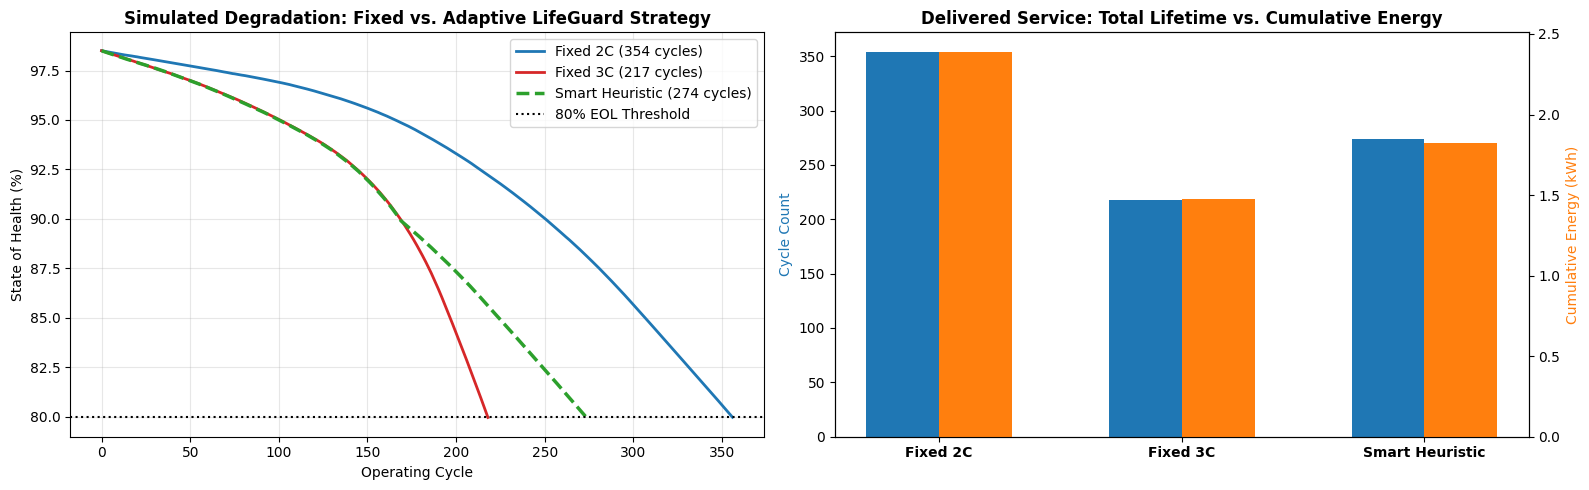

[Figure Saved] reports_gemini/figures/09_policy_comparison_digital_twin.png


In [70]:
# 9. Visualizing Policy Performance in Digital Twin
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Simulated SOH Degradation Curves Under the 3 Policies
axes[0].plot(res_2c['sample_trajectory'], label=f"Fixed 2C ({res_2c['mean_lifetime_cycles']:.0f} cycles)", color='#1f77b4', lw=2)
axes[0].plot(res_3c['sample_trajectory'], label=f"Fixed 3C ({res_3c['mean_lifetime_cycles']:.0f} cycles)", color='#d62728', lw=2)
axes[0].plot(res_smart['sample_trajectory'], label=f"Smart Heuristic ({res_smart['mean_lifetime_cycles']:.0f} cycles)", color='#2ca02c', lw=2.5, linestyle='--')
axes[0].axhline(80.0, color='black', linestyle=':', label='80% EOL Threshold')
axes[0].set_title('Simulated Degradation: Fixed vs. Adaptive LifeGuard Strategy', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Operating Cycle')
axes[0].set_ylabel('State of Health (%)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: Total Energy Delivered (kWh) vs. Cycle Life
strategies = ['Fixed 2C', 'Fixed 3C', 'Smart Heuristic']
lifetimes = [res_2c['mean_lifetime_cycles'], res_3c['mean_lifetime_cycles'], res_smart['mean_lifetime_cycles']]
energies = [res_2c['mean_energy_kwh'], res_3c['mean_energy_kwh'], res_smart['mean_energy_kwh']]

bar1 = axes[1].bar(np.arange(3) - 0.15, lifetimes, width=0.3, label='Cycles to EOL', color='#1f77b4')
ax2 = axes[1].twinx()
bar2 = ax2.bar(np.arange(3) + 0.15, energies, width=0.3, label='Delivered Energy (kWh)', color='#ff7f0e')

axes[1].set_xticks(np.arange(3))
axes[1].set_xticklabels(strategies, fontweight='bold')
axes[1].set_ylabel('Cycle Count', color='#1f77b4')
ax2.set_ylabel('Cumulative Energy (kWh)', color='#ff7f0e')
axes[1].set_title('Delivered Service: Total Lifetime vs. Cumulative Energy', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('reports_gemini/figures/09_policy_comparison_digital_twin.png', dpi=300)
plt.show()
print("[Figure Saved] reports_gemini/figures/09_policy_comparison_digital_twin.png")


In [71]:
# 10. Export Simulation Benchmark & Auto-Zip for Kaggle Download
df_res.to_csv('reports_gemini/simulator_policy_benchmark.csv', index=False)
print("[Metrics Saved] reports_gemini/simulator_policy_benchmark.csv")

# Auto-archive reports directory into reports_gemini.zip
shutil.make_archive('reports_gemini', 'zip', 'reports_gemini')
print("\n[Archive Ready] Successfully generated 'reports_gemini.zip'! Download it from Kaggle's Output panel.")


[Metrics Saved] reports_gemini/simulator_policy_benchmark.csv

[Archive Ready] Successfully generated 'reports_gemini.zip'! Download it from Kaggle's Output panel.
